### *PhotoDissociation Region Toolbox Notebooks*
-------------------------------------------------------------

# Spatial-Domain Regularization: Smoothing Density and Radiation Field Maps
## Table of Contents

* [Introduction](#introduction)
* [Import Python modules](#import)
* [Build a synthetic 50x50 map](#build)
* [Run the fit with no phase-space restriction](#run)
* [Plot the fitted maps -- salt-and-pepper noise is visible](#plotmaps)
* [This is not the same problem as the N22 notebooks](#notn22)
* [Apply regularization](#regularize)
* [Plot the regularized maps](#plotreg)
* [Quantify the improvement against the known truth](#quantify)
* [The genuine extended feature is preserved, not blurred away](#block)
* [Choosing lambda: a science parameter, not just a smoothing knob](#lambda)
* [Conclusion](#conclusion)

---------------------------
## Introduction <a id="introduction"></a>
-------------------------------

The [Determining Radiation Field and Density from Images](PDRT_Example_Make_n_G0_maps.ipynb) notebook shows a real problem: when you fit $G_0$ and $n$ independently at every pixel, individual pixels can land on either of two mathematically acceptable solutions with similar $\chi^2$ but very different physical values. In that notebook, the fix was to restrict the acceptable model phase space (`radiation_field_range`/`density_range`) using outside knowledge of the source, because *the whole map* was torn between the two solutions -- a genuine, map-wide degeneracy that spatial smoothness alone cannot and should not resolve (smoothing data apart that is genuinely ambiguous would just be guessing).

This notebook demonstrates a different, equally common situation: most of a map has one clear, well-constrained solution, but a handful of *individual* pixels are noisy outliers -- "salt and pepper" misfits caused by ordinary measurement noise, not a competing physical solution. For *this* kind of problem, `LineRatioFit.regularize()` can clean up the map directly, with **no** phase-space restriction, because smoothing toward the neighbor consensus is the scientifically correct thing to do when a lone pixel disagrees with everything around it.

Because real data never comes with a known "right answer," we build a **synthetic** map here: we pick the true density and radiation field at every pixel ourselves, forward-model what `LineRatioFit` would observe, add realistic noise, and then deliberately inject salt-and-pepper outliers into a handful of pixels' data. This lets us check, quantitatively, that `regularize()` moves pixels *back toward the truth we know we started with* -- something we can never do with real observations. The map also contains one genuinely different, spatially-extended region (a $12\times12$ block) standing in for a real feature like a clump or an ionization front, so we can also check that regularization does *not* erase real structure while it's cleaning up noise.

See the [spatial regularization documentation](https://pdrtpy.readthedocs.io/en/latest/pdrtpy.regularization.html) for the full API, and its linked background-reading pages on [ISTA](https://pdrtpy.readthedocs.io/en/latest/ista.html) and [Chambolle's algorithm](https://pdrtpy.readthedocs.io/en/latest/chambolle.html) for the plain-language explanation of how the solver works under the hood.

The first step is to import the modules we will need. <a id="import"></a>

In [1]:
from pdrtpy.measurement import Measurement
from pdrtpy.modelset import ModelSet
from pdrtpy.tool.lineratiofit import LineRatioFit
from pdrtpy.plot.lineratioplot import LineRatioPlot
import numpy as np
import matplotlib.pyplot as plt
from astropy.nddata import StdDevUncertainty
from astropy.wcs import WCS

# don't show some matplotlib/numpy warnings
import warnings
warnings.filterwarnings("ignore", message="invalid value encountered in do_format")
warnings.filterwarnings("ignore", category=RuntimeWarning)

------------------------------------------------------------
## Build a synthetic 50x50 map <a id="build"></a>
------------------------------------------------------------
We will use the `wk2020` model set and the same four lines ([O I] 63 $\mu$m, [C I] 609 $\mu$m, CO(4-3), and [C II] 158 $\mu$m) used in the [Find n and G0 for a single pixel](PDRT_Example_Find_n_G0_Single_Pixel.ipynb) example. All four have their own intensity models in `wk2020`, so we can forward-model each line's true intensity directly from a chosen $(n, G_0)$ with `ModelSet.get_models(..., model_type="intensity")` -- no need to invert ratios.

The recipe:

1. Pick a single, well-constrained "background" solution and forward-model its true line intensities.
2. Pick a second, well-separated solution for one $12\times12$ block of pixels -- a stand-in for a genuine, spatially-extended feature.
3. Add realistic (10%, matching typical observational S/N) multiplicative Gaussian noise to every pixel's flux.
4. At a scattered set of isolated pixels (never touching each other, and never inside or next to the block), give one line (CO(4-3)) an extra, larger noise excursion -- simulating an ordinary few-sigma outlier in the *data*, not a different true $(n, G_0)$.

In [2]:
wk2020 = ModelSet("wk2020", z=1)
line_ids = ["OI_63", "CI_609", "CO_43", "CII_158"]
intensity_models = wk2020.get_models(line_ids, model_type="intensity")

def true_intensities(n, g0):
    """The true (noiseless) intensity of every line at one (density, radiation_field) point."""
    return {line_id: intensity_models[line_id].get(n, g0) for line_id in line_ids}

In [3]:
# Background "truth": a single, well-constrained solution (~20 Habing, 1e4 cm^-3).
branch_background = (1.0e4, 0.032)
# A second, independent, well-separated solution used only for the extended block feature.
branch_feature = (1.0e6, 1.0)

shape = (50, 50)
noise = 0.10
outlier_line = "CO_43"
outlier_n_sigma = 2.5
n_scattered = 90
block_row0, block_col0, block_size = 32, 8, 12
rng = np.random.default_rng(99)

truth_background = true_intensities(*branch_background)
truth_feature = true_intensities(*branch_feature)

In [4]:
def in_or_near_block(r, c, pad=1):
    """True if (r, c) falls inside the block, or within `pad` pixels of it."""
    return (block_row0 - pad <= r < block_row0 + block_size + pad) and (
        block_col0 - pad <= c < block_col0 + block_size + pad
    )

# Choose non-adjacent scattered pixel coordinates, excluding the block's footprint.
scattered_coords = []
tries = 0
while len(scattered_coords) < n_scattered and tries < 200000:
    tries += 1
    r, c = rng.integers(1, shape[0] - 1), rng.integers(1, shape[1] - 1)
    if in_or_near_block(r, c):
        continue
    if all(abs(r - rr) > 1 or abs(c - cc) > 1 for rr, cc in scattered_coords):
        scattered_coords.append((int(r), int(c)))
print(f"Placed {len(scattered_coords)} scattered outlier pixels.")

Placed 90 scattered outlier pixels.


In [5]:
# A simple synthetic sky WCS, purely for display -- the coordinates are not meaningful.
wcs = WCS(naxis=2)
wcs.wcs.crpix = [shape[1] / 2, shape[0] / 2]
wcs.wcs.cdelt = [-1 / 3600, 1 / 3600]
wcs.wcs.crval = [16.0, -72.5]
wcs.wcs.ctype = ["RA---TAN", "DEC--TAN"]
wcs._naxis = [shape[1], shape[0]]

true_flux = {line_id: np.full(shape, truth_background[line_id]) for line_id in line_ids}
for line_id in line_ids:
    true_flux[line_id][block_row0:block_row0 + block_size, block_col0:block_col0 + block_size] = truth_feature[line_id]

noisy_flux = {line_id: true_flux[line_id] * (1 + rng.normal(0, noise, shape)) for line_id in line_ids}
for r, c in scattered_coords:
    noisy_flux[outlier_line][r, c] = truth_background[outlier_line] * (1 + outlier_n_sigma * noise)

measurements = [
    Measurement(
        data=noisy_flux[line_id],
        uncertainty=StdDevUncertainty(noise * np.abs(true_flux[line_id])),
        identifier=line_id,
        unit=str(intensity_models[line_id].unit),
        wcs=wcs,
    )
    for line_id in line_ids
]

--------------------------------------------
## Run the fit with no phase-space restriction <a id="run"></a>
--------------------------------------------
We call `run()` exactly as in the [n, G0 maps example](PDRT_Example_Make_n_G0_maps.ipynb) -- `joint_fit='fast'` for speed -- but we do **not** pass `radiation_field_range` or `density_range`. The fit sees only the noisy flux maps; it has no idea which pixels we deliberately perturbed.

In [6]:
p = LineRatioFit(modelset=wk2020, measurements=measurements)
p.run(joint_fit="fast", workers=6)
print("Mean density: %.3E %s" % (np.nanmean(p.density), p.density.unit))
print("Mean radiation field: %.3E %s" % (np.nanmean(p.radiation_field), p.radiation_field.unit))

Mean density: 6.595E+04 1 / cm3
Mean radiation field: 8.604E-02 erg / (s cm2)


-------------------------------
## Plot the fitted maps -- salt-and-pepper noise is visible <a id="plotmaps"></a>
-------------------------------

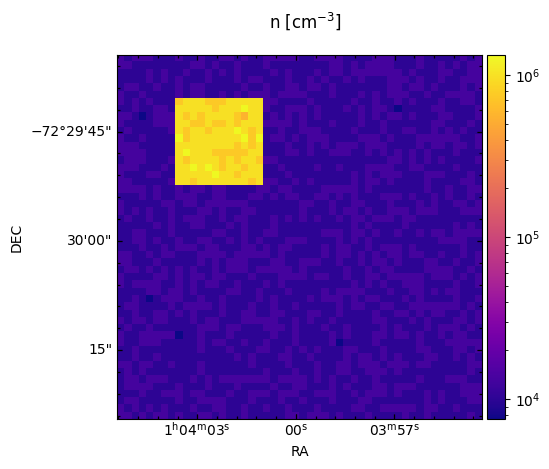

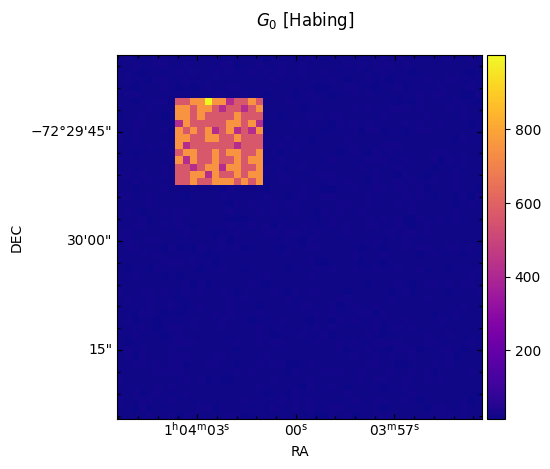

In [7]:
plot = LineRatioPlot(p)
plot.density(norm="log")
plot.radiation_field(units="Habing", norm="simple")

----------------------------------------------------
## This is not the same problem as the N22 notebooks <a id="notn22"></a>
----------------------------------------------------
You can see the scattered single-pixel defects, and the one genuinely different $12\times12$ block. Unlike the N22 maps, this is *not* a map torn between two competing solutions: a histogram of the fitted density shows one dominant peak at the true background value, plus the small, separate population from the one real feature -- not a map-wide, roughly 50/50 split the way N22's phase-space ambiguity produces. That difference is exactly why regularizing *this* map, with no phase-space restriction, is the right thing to do.

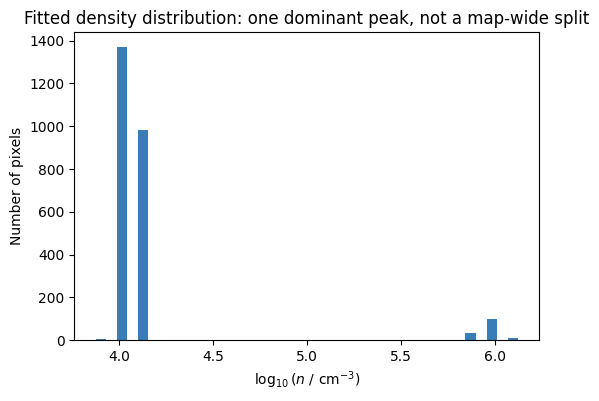

In [8]:
valid = ~np.isnan(p.density.data)
plt.figure(figsize=(6, 4))
plt.hist(np.log10(p.density.data[valid]), bins=40)
plt.xlabel(r"$\log_{10}(n$ / cm$^{-3})$")
plt.ylabel("Number of pixels")
plt.title("Fitted density distribution: one dominant peak, not a map-wide split")
plt.show()

--------------------------------
## Apply regularization <a id="regularize"></a>
--------------------------------
`regularize()` runs *after* `run()`, as a separate step -- it never touches the original per-pixel fit, which remains available via `p.density`/`p.radiation_field`. We use the recommended `method="tv"` (isotropic Total Variation), which suppresses isolated disagreements without blurring real, spatially-extended structure -- unlike a Tikhonov (`method="tikhonov"`) penalty, which would blur the block along with the noise. `lam` (the regularization strength) and `max_iter` were tuned for this map; see [Choosing lambda](#lambda) below for what happens with other values.

In [9]:
density_regularized, radiation_field_regularized = p.regularize(method="tv", lam=25, max_iter=300)

-------------------------------
## Plot the regularized maps <a id="plotreg"></a>
-------------------------------
Pass `regularized=True` to plot the cleaned-up maps instead of the original fit.

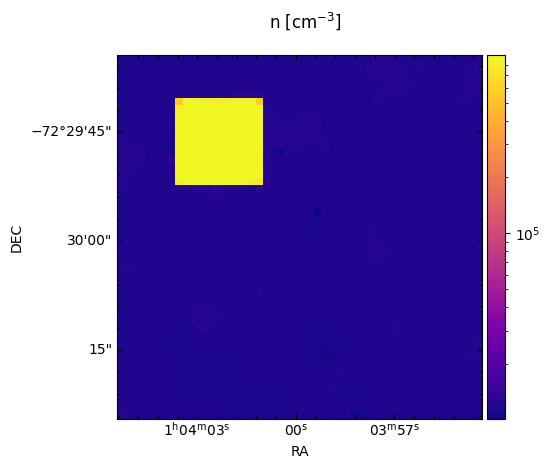

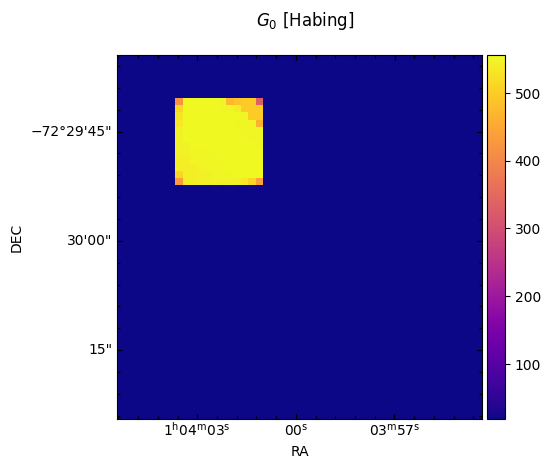

In [10]:
plot.density(regularized=True, norm="log")
plot.radiation_field(units="Habing", regularized=True, norm="simple")

----------------------------------------------------------
## Quantify the improvement against the known truth <a id="quantify"></a>
----------------------------------------------------------
With real data you cannot do this -- you don't know the true answer. Because this map is synthetic, we do, so we can directly check that regularization moved the deliberately-perturbed pixels *back toward the truth we started with*.

In [11]:
log_true_background = np.log10(branch_background[0])
log_density_fit = np.log10(p.density.data)
log_density_regularized = np.log10(density_regularized.data)

error_before = np.array([abs(log_density_fit[r, c] - log_true_background) for r, c in scattered_coords])
error_after = np.array([abs(log_density_regularized[r, c] - log_true_background) for r, c in scattered_coords])

print(f"Mean |log10(n) error| at the {len(scattered_coords)} scattered pixels:")
print(f"  before regularizing: {error_before.mean():.4f} dex")
print(f"  after  regularizing: {error_after.mean():.4f} dex")
print(f"  fraction of pixels improved: {np.mean(error_after < error_before):.0%}")

Mean |log10(n) error| at the 90 scattered pixels:
  before regularizing: 0.1222 dex
  after  regularizing: 0.0673 dex
  fraction of pixels improved: 98%


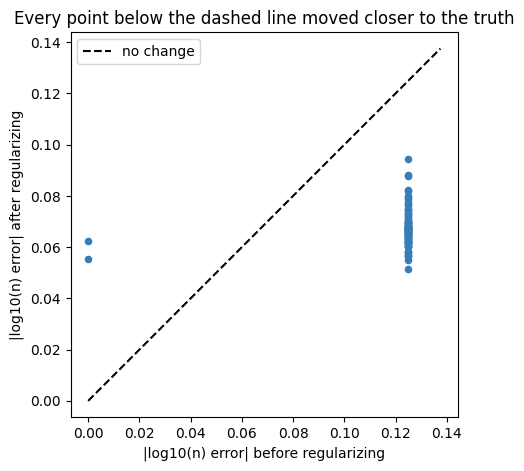

In [12]:
plt.figure(figsize=(5, 5))
plt.scatter(error_before, error_after, s=20)
lim = max(error_before.max(), error_after.max()) * 1.1
plt.plot([0, lim], [0, lim], "k--", label="no change")
plt.xlabel("|log10(n) error| before regularizing")
plt.ylabel("|log10(n) error| after regularizing")
plt.title("Every point below the dashed line moved closer to the truth")
plt.legend()
plt.axis("equal")
plt.show()

----------------------------------------------------------------
## The genuine extended feature is preserved, not blurred away <a id="block"></a>
----------------------------------------------------------------
The $12\times12$ block is a real, spatially-supported feature -- unlike the isolated scattered pixels, it has many neighbors that agree with it. Total Variation regularization is designed to leave exactly this kind of structure alone while still cleaning up isolated noise.

In [13]:
block_rows = slice(block_row0, block_row0 + block_size)
block_cols = slice(block_col0, block_col0 + block_size)

block_before = log_density_fit[block_rows, block_cols]
block_after = log_density_regularized[block_rows, block_cols]
block_true = np.log10(branch_feature[0])
block_change = np.abs(block_after - block_before).mean()
scattered_change = np.abs(error_after - error_before).mean()
block_separation = block_true - log_true_background

print(f"Block mean log10(n): true={block_true:.3f}  before={block_before.mean():.3f}  after={block_after.mean():.3f}")
print(f"Mean change in the block: {block_change:.4f} dex")
print(f"For comparison, the scattered pixels moved {scattered_change:.4f} dex on average, and the block sits {block_separation:.2f} dex from the background")

Block mean log10(n): true=6.000  before=5.977  after=5.946
Mean change in the block: 0.0660 dex
For comparison, the scattered pixels moved 0.0575 dex on average, and the block sits 2.00 dex from the background


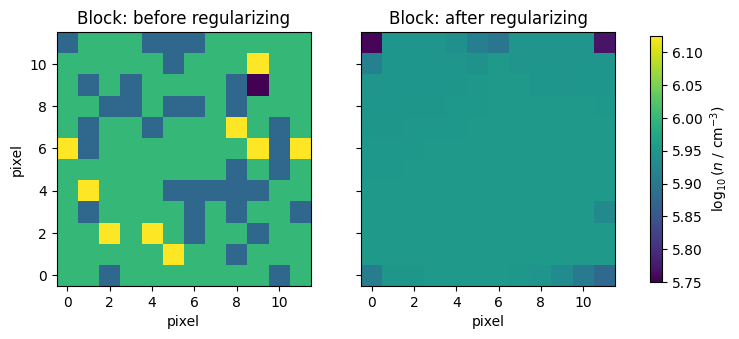

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
im0 = axes[0].imshow(block_before, origin="lower", vmin=block_before.min(), vmax=block_before.max())
axes[0].set_title("Block: before regularizing")
im1 = axes[1].imshow(block_after, origin="lower", vmin=block_before.min(), vmax=block_before.max())
axes[1].set_title("Block: after regularizing")
for ax in axes:
    ax.set_xlabel("pixel")
axes[0].set_ylabel("pixel")
fig.colorbar(im1, ax=axes, label=r"$\log_{10}(n$ / cm$^{-3})$", shrink=0.8)
plt.show()

------------------------------------------------------------------------
## Choosing lambda: a science parameter, not just a smoothing knob <a id="lambda"></a>
------------------------------------------------------------------------
`lam` controls how strongly regularization pulls a disagreeing pixel toward its neighbors. Because the penalty acts in log10-space, it governs which discontinuities get treated as noise versus signal -- too small, and nothing visible happens; too large, and it starts eroding the genuine block along with the noise. We check three values here: much smaller, the value used above, and much larger than what worked.

In [15]:
for lam in [2, 25, 150]:
    d_reg, _ = p.regularize(method="tv", lam=lam, max_iter=300)
    log_d_reg = np.log10(d_reg.data)
    err = np.array([abs(log_d_reg[r, c] - log_true_background) for r, c in scattered_coords]).mean()
    block_change = np.abs(log_d_reg[block_rows, block_cols] - block_before).mean()
    print(f"lam={lam:>4}:  scattered-pixel mean error={err:.4f} dex   block change={block_change:.4f} dex")

lam=   2:  scattered-pixel mean error=0.1100 dex   block change=0.0291 dex


lam=  25:  scattered-pixel mean error=0.0673 dex   block change=0.0660 dex


lam= 150:  scattered-pixel mean error=0.0671 dex   block change=0.2069 dex


At `lam=2` the correction is much weaker than at `lam=25`; at `lam=150` the scattered-pixel correction barely improves any further, but the block starts moving noticeably more -- regularization strong enough to also start eroding real structure. `lam=25` is close to the best trade-off for this particular map: strong enough to clean up the noise, gentle enough to leave the real feature alone. This is why `regularize()`'s documentation calls `lam` a science parameter rather than a tuning knob to maximize blindly.

-------------------------
## Conclusion <a id="conclusion"></a>
-------------------------
On a map with a single, well-constrained solution plus isolated noise-driven outliers and one genuine extended feature, `LineRatioFit.regularize(method="tv")` corrects the outliers substantially -- verified here against known ground truth -- while leaving the real feature essentially untouched, with **no** `density_range`/`radiation_field_range` restriction anywhere.

This is a different situation from the [Determining Radiation Field and Density from Images](PDRT_Example_Make_n_G0_maps.ipynb) and [regularization-on-real-data](test_regularize.ipynb) notebooks, where the *entire* N22 map is torn between two competing solutions. That is a genuine physical degeneracy that spatial smoothness cannot and should not resolve by itself -- it needs the external information encoded in `radiation_field_range`/`density_range`. The lesson from both notebooks together: use phase-space restriction to resolve a real, map-wide solution ambiguity, and use `regularize()` afterward (or alone, as here, when there is no such ambiguity) to clean up genuine pixel-to-pixel noise.